# Mini Interconnect: Power Flow studies with pandapower
Exploring AC power flow on IEEE test systems

## 1. Setup and IEEE 14-bus base case

In [83]:
import pandapower as pp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandapower.networks.power_system_test_cases import case14, case118

net14 = case14() # Load the IEEE 14-bus test case
pp.runpp(net14)  # Run power flow analysis
V_MIN, V_MAX = 0.95, 1.05  # Define voltage limits

## 2. Bus classification (Slack / PV / PQ)

In [84]:
# initial value as a pq bus
bus_types = pd.Series("PQ", index=net14.bus.index, name="type")

# if it has a generator in service, it's actually pv
generators = net14.gen[net14.gen.in_service]
bus_types.loc[generators.bus] = "PV"

# if its connected an external grid, its a slack bus
external_grid_buses = net14.ext_grid[net14.ext_grid.in_service].bus
bus_types.loc[external_grid_buses] = "Slack"

# print table
table = pd.concat([bus_types, net14.res_bus], axis=1)
table.index.name = "Bus"
display(table)
display(bus_types.value_counts().to_frame("count"))

,type,vm_pu,va_degree,p_mw,q_mvar
Bus,,,,,
0,Slack,1.060000,0.000000,-232.393272,16.549301
1,PV,1.045000,-4.982589,-18.300000,-30.857100
2,PV,1.010000,-12.725100,94.200000,-6.075348
3,PQ,1.017671,-10.312901,47.800000,-3.900000
4,PQ,1.019514,-8.773854,7.600000,1.600000
5,PV,1.070000,-14.220946,11.200000,-5.230944
6,PQ,1.061520,-13.359627,0.000000,0.000000
7,PV,1.090000,-13.359627,0.000000,-17.623451
8,PQ,1.055932,-14.938521,29.500000,-4.584844


,count
type,
PQ,9
PV,4
Slack,1


In [85]:
display(net14.res_line[["loading_percent"]].round(3))

,loading_percent
0,1.508
1,0.721
2,0.709
3,0.543
4,0.403
5,0.240
6,0.627
7,0.077
8,0.077
9,0.181


## 3. Voltage profile

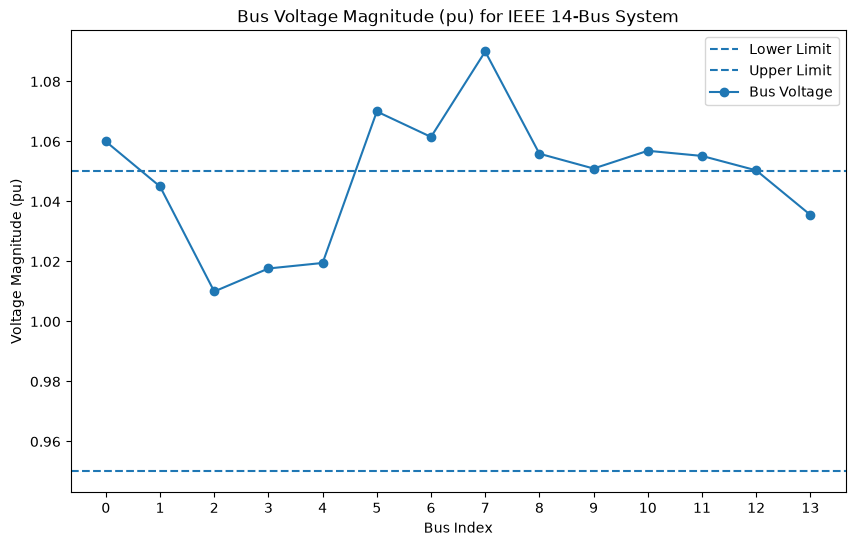

In [86]:
# plot vm_pu (voltage magnitude)
buses = net14.bus.index
vm_pu = net14.res_bus["vm_pu"]
figure = plt.figure(figsize=(10, 6))
plt.axhline(y=V_MIN, label="Lower Limit", linestyle="--")
plt.axhline(y=V_MAX, label="Upper Limit", linestyle="--")
plt.plot(buses, vm_pu, marker="o", linestyle="-", label="Bus Voltage")
plt.xticks(buses)
plt.xlabel("Bus Index")
plt.ylabel("Voltage Magnitude (pu)")
plt.title("Bus Voltage Magnitude (pu) for IEEE 14-Bus System")
plt.legend()
plt.show()

## 4. Load scaling study: how far can we push the 14-bus system?

In [87]:
results = [ ]
net14_scaled = case14() # Load the IEEE 14-bus test case

for s in np.round(np.arange(0.5, 3.01, 0.05), 2): # start, stop, step
    net14_scaled.load.scaling = s
    try:
        pp.runpp(net14_scaled, enforce_q_lims=True)
    except pp.LoadflowNotConverged as e:
        results.append((s, None, None, "diverged"))
        break
    vmin = net14_scaled.res_bus.vm_pu.min()
    lmax = net14_scaled.res_line.loading_percent.max()
    results.append((s, vmin, lmax, "ok"))

net14.load.scaling = 1.0
result_frame = pd.DataFrame(results, columns=["scaling", "vmin", "lmax", "status"])
display(result_frame)

,scaling,vmin,lmax,status
0,0.50,1.020725,0.569543,ok
1,0.55,1.016849,0.654937,ok
2,0.60,1.012939,0.743238,ok
3,0.65,1.010000,0.834338,ok
4,0.70,1.010000,0.927623,ok
5,0.75,1.010000,1.022013,ok
6,0.80,1.010000,1.117391,ok
7,0.85,1.010000,1.213678,ok
8,0.90,1.010000,1.310823,ok
9,0.95,1.010000,1.408793,ok


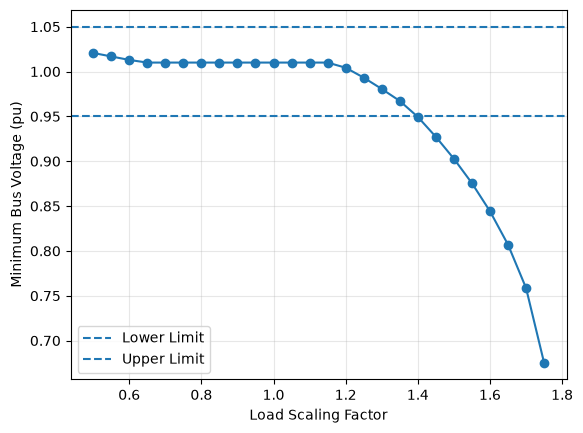

In [88]:
plt.plot(result_frame.scaling, result_frame.vmin, marker="o")
plt.axhline(y=V_MIN, label="Lower Limit", linestyle="--")
plt.axhline(y=V_MAX, label="Upper Limit", linestyle="--")
plt.xlabel("Load Scaling Factor")
plt.ylabel("Minimum Bus Voltage (pu)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Scaling up: IEEE 118-bus summary

In [89]:
net118 = case118()

pp.runpp(net118)

min_vm = net118.res_bus["vm_pu"].min()
print(f"Minimum voltage: {min_vm:.3f} p.u.")
max_vm = net118.res_bus["vm_pu"].max()
print(f"Maximum voltage: {max_vm:.3f} p.u.")
max_line_loading = net118.res_line["loading_percent"].max()
print(f"Maximum line loading: {max_line_loading:.3f} %")
max_trafo_loading = net118.res_trafo["loading_percent"].max()
print(f"Maximum transformer loading: {max_trafo_loading:.3f} %")

total_losses = net118.res_line["pl_mw"].sum() + net118.res_trafo["pl_mw"].sum()
print(f"Total system losses: {total_losses:.3f} MW")

Minimum voltage: 0.943 p.u.
Maximum voltage: 1.050 p.u.
Maximum line loading: 4.475 %
Maximum transformer loading: 3.590 %
Total system losses: 133.170 MW


In [96]:
def run_powerflow(net):
    pp.runpp(net, enforce_q_lims=True)
    vm = net.res_bus.vm_pu
    return {
        "vmin_pu": round(vm.min(), 3),
        "vmin_bus": vm.idxmin(),
        "vmax_pu": round(vm.max(), 3),
        "vmax_bus": vm.idxmax(),
        "max_line_loading_percent": round(net.res_line.loading_percent.max(), 3),
        "max_line": net.res_line.loading_percent.idxmax(),
        "max_trafo_loading_percent": round(net.res_trafo.loading_percent.max(), 3),
        "losses_mw": round(net.res_line.pl_mw.sum() + net.res_trafo.pl_mw.sum(), 3),
    }

print("IEEE 118-Bus System Power Flow Summary:")
summary118 = run_powerflow(case118())
for k, v in summary118.items():
    print(f"{k}: {v}")

print("\n")

print("IEEE 14-Bus System Power Flow Summary:")
summary14 = run_powerflow(case14())
for k, v in summary14.items():
    print(f"{k}: {v}")


IEEE 118-Bus System Power Flow Summary:
vmin_pu: 0.943
vmin_bus: 75
vmax_pu: 1.05
vmax_bus: 24
max_line_loading_percent: 4.475
max_line: 6
max_trafo_loading_percent: 3.589
losses_mw: 132.788


IEEE 14-Bus System Power Flow Summary:
vmin_pu: 1.01
vmin_bus: 2
vmax_pu: 1.09
vmax_bus: 7
max_line_loading_percent: 1.508
max_line: 0
max_trafo_loading_percent: 0.454
losses_mw: 13.393
